# Test-Set Comparison: YOLOv8n vs YOLOv8s vs YOLOv5s

This notebook loads the best weights from the three training notebooks and evaluates each model on the same RDD2022 **test set**. It reports Precision, Recall, mAP@0.5, mAP@0.5:0.95, inference time and FPS, gives per-class results, and plots the comparison.

**Before running:** the three `best.pt` files must be added as Kaggle inputs.

**Note:** the overall comparison table (section 6) and the YOLOv5s per-class table (section 8) contain values typed in from the evaluation outputs printed above them, so re-running the evaluations will not update those tables automatically.

## 1. Environment and inputs

Checks the Python, PyTorch and GPU setup and lists what is available under `/kaggle/input`, including every `best.pt` file found.

In [4]:
import os
import sys
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}:", torch.cuda.get_device_name(i))

Python: 3.12.13
PyTorch: 2.10.0+cu128
CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


In [5]:
from pathlib import Path

INPUT_ROOT = Path("/kaggle/input")

print("Available Kaggle inputs:")
print("=" * 80)

for item in sorted(INPUT_ROOT.iterdir()):
    print(item)

Available Kaggle inputs:
/kaggle/input/datasets
/kaggle/input/notebooks


In [6]:
best_weights = list(Path("/kaggle/input").rglob("best.pt"))

print(f"Found {len(best_weights)} best.pt files")
print("=" * 100)

for i, path in enumerate(best_weights):
    print(f"[{i}] {path}")

Found 3 best.pt files
[0] /kaggle/input/notebooks/sultanhaidercheema/yolov5s/RoadDamageProject/YOLOv5s_RDD2022_5class/weights/best.pt
[1] /kaggle/input/notebooks/sultanhaidercheema/yolov8snew/RoadDamageProject/YOLOv8s_RDD2022_5class/weights/best.pt
[2] /kaggle/input/notebooks/sultanhaidercheema/yolov8n/RoadDamageProject/YOLOv8n_RDD2022_5class/weights/best.pt


## 2. Locate the weights, test data and config

Picks the YOLOv8n, YOLOv8s and YOLOv5s `best.pt` files by folder name, finds the `RDD_SPLIT` dataset, counts the test images and labels, and writes a YAML file that points to the test split.

In [7]:
V8N_WEIGHTS = None
V8S_WEIGHTS = None
V5S_WEIGHTS = None

for path in best_weights:
    path_text = str(path).lower()

    if "yolov8n" in path_text:
        V8N_WEIGHTS = path

    elif "yolov8s" in path_text:
        V8S_WEIGHTS = path

    elif "yolov5s" in path_text:
        V5S_WEIGHTS = path


print("YOLOv8n:")
print(V8N_WEIGHTS)

print("\nYOLOv8s:")
print(V8S_WEIGHTS)

print("\nYOLOv5s:")
print(V5S_WEIGHTS)


assert V8N_WEIGHTS is not None, "YOLOv8n best.pt not found"
assert V8S_WEIGHTS is not None, "YOLOv8s best.pt not found"
assert V5S_WEIGHTS is not None, "YOLOv5s best.pt not found"

print("\n✅ All three model weights found successfully.")

YOLOv8n:
/kaggle/input/notebooks/sultanhaidercheema/yolov8n/RoadDamageProject/YOLOv8n_RDD2022_5class/weights/best.pt

YOLOv8s:
/kaggle/input/notebooks/sultanhaidercheema/yolov8snew/RoadDamageProject/YOLOv8s_RDD2022_5class/weights/best.pt

YOLOv5s:
/kaggle/input/notebooks/sultanhaidercheema/yolov5s/RoadDamageProject/YOLOv5s_RDD2022_5class/weights/best.pt

✅ All three model weights found successfully.


In [8]:
possible_rdd_paths = []

for path in Path("/kaggle/input").rglob("RDD_SPLIT"):
    if path.is_dir():
        possible_rdd_paths.append(path)

print("RDD_SPLIT directories found:")
for path in possible_rdd_paths:
    print(path)

assert len(possible_rdd_paths) > 0, "RDD_SPLIT dataset not found"

DATASET_ROOT = possible_rdd_paths[0]

print("\nUsing dataset:")
print(DATASET_ROOT)

RDD_SPLIT directories found:
/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT

Using dataset:
/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT


In [9]:
TEST_IMAGES = DATASET_ROOT / "test" / "images"
TEST_LABELS = DATASET_ROOT / "test" / "labels"

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

test_images = [
    path for path in TEST_IMAGES.iterdir()
    if path.suffix.lower() in image_extensions
]

test_labels = list(TEST_LABELS.glob("*.txt"))

print("Test images:", len(test_images))
print("Test labels:", len(test_labels))

assert TEST_IMAGES.exists()
assert TEST_LABELS.exists()
assert len(test_images) > 0

print("\n✅ Test dataset ready.")

Test images: 5758
Test labels: 5758

✅ Test dataset ready.


In [10]:
import yaml

TEST_YAML = Path("/kaggle/working/rdd2022_5class_test.yaml")

data_config = {
    "path": str(DATASET_ROOT),
    "train": "train/images",
    "val": "val/images",
    "test": "test/images",
    "nc": 5,
    "names": [
        "longitudinal crack",
        "transverse crack",
        "alligator crack",
        "other corruption",
        "Pothole",
    ],
}

with open(TEST_YAML, "w") as f:
    yaml.safe_dump(
        data_config,
        f,
        sort_keys=False
    )

print(TEST_YAML.read_text())

path: /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT
train: train/images
val: val/images
test: test/images
nc: 5
names:
- longitudinal crack
- transverse crack
- alligator crack
- other corruption
- Pothole



## 3. Evaluate YOLOv8n

Installs Ultralytics and runs validation on the test split (image size 640, batch size 16). Then prints the overall metrics, the per-class metrics and the speed. FPS is calculated as 1000 divided by the inference time in milliseconds.

In [11]:
!pip install -q ultralytics

from ultralytics import YOLO
import pandas as pd
import time
from pathlib import Path

print("Ultralytics imported successfully.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 18.1 MB/s eta 0:00:0000:0100:01
Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics imported successfully.


In [12]:
V8N_TEST_DIR = Path("/kaggle/working/test_results/yolov8n")

model_v8n = YOLO(str(V8N_WEIGHTS))

start_time = time.time()

metrics_v8n = model_v8n.val(
    data=str(TEST_YAML),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,
    save_json=False,
    project="/kaggle/working/test_results",
    name="yolov8n",
    exist_ok=True
)

v8n_total_time = time.time() - start_time

print("\nYOLOv8n test evaluation complete.")
print(f"Total evaluation time: {v8n_total_time:.2f} seconds")

Ultralytics 8.4.117 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,006,623 parameters, 0 gradients, 8.1 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 11.7±11.9 MB/s, size: 425.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/test/labels... 5758 images, 1790 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5758/5758 163.7it/s 35.2s0.0ss
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 360/360 4.9it/s 1:140.2sss
                   all       5758       9675      0.618      0.544      0.571      0.306
    longitudinal crack       2080       3925      0.596      0.515     

In [13]:
v8n_precision = metrics_v8n.box.mp
v8n_recall = metrics_v8n.box.mr
v8n_map50 = metrics_v8n.box.map50
v8n_map5095 = metrics_v8n.box.map

print("YOLOv8n Test Metrics")
print("=" * 50)
print(f"Precision:      {v8n_precision:.4f}")
print(f"Recall:         {v8n_recall:.4f}")
print(f"mAP@0.5:        {v8n_map50:.4f}")
print(f"mAP@0.5:0.95:   {v8n_map5095:.4f}")

YOLOv8n Test Metrics
Precision:      0.6181
Recall:         0.5439
mAP@0.5:        0.5712
mAP@0.5:0.95:   0.3056


In [14]:
v8n_class_rows = []

for class_id, class_name in metrics_v8n.names.items():
    v8n_class_rows.append({
        "Class ID": class_id,
        "Class Name": class_name,
        "Precision": metrics_v8n.box.p[class_id],
        "Recall": metrics_v8n.box.r[class_id],
        "mAP50": metrics_v8n.box.ap50[class_id],
        "mAP50-95": metrics_v8n.box.maps[class_id]
    })

v8n_per_class = pd.DataFrame(v8n_class_rows)

display(v8n_per_class)

,Class ID,Class Name,Precision,Recall,mAP50,mAP50-95
0,0,longitudinal crack,0.596041,0.515159,0.538537,0.296153
1,1,transverse crack,0.571494,0.518806,0.522995,0.253692
2,2,alligator crack,0.656028,0.585689,0.641208,0.338665
3,3,other corruption,0.649174,0.726528,0.721788,0.448060
4,4,Pothole,0.617564,0.373564,0.431501,0.191260


In [15]:
print("YOLOv8n Speed Information")
print("=" * 50)
print(metrics_v8n.speed)

inference_ms_v8n = metrics_v8n.speed["inference"]

fps_v8n = 1000 / inference_ms_v8n

print(f"\nInference time: {inference_ms_v8n:.3f} ms/image")
print(f"Approximate FPS: {fps_v8n:.2f}")

YOLOv8n Speed Information
{'preprocess': 0.87561759013538, 'inference': 3.4479745369919352, 'loss': 0.0007321498779267381, 'postprocess': 0.9274022004167279}

Inference time: 3.448 ms/image
Approximate FPS: 290.03


## 4. Evaluate YOLOv8s

The same steps as above, for YOLOv8s.

In [16]:
V8S_TEST_DIR = Path("/kaggle/working/test_results/yolov8s")

model_v8s = YOLO(str(V8S_WEIGHTS))

start_time = time.time()

metrics_v8s = model_v8s.val(
    data=str(TEST_YAML),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,
    save_json=False,
    project="/kaggle/working/test_results",
    name="yolov8s",
    exist_ok=True
)

v8s_total_time = time.time() - start_time

print("\nYOLOv8s test evaluation complete.")
print(f"Total evaluation time: {v8s_total_time:.2f} seconds")

Ultralytics 8.4.117 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 11,127,519 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 375.4±520.5 MB/s, size: 265.9 KB)
val: Scanning /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/test/labels... 5758 images, 1790 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5758/5758 1.1Kit/s 5.5s0.1ss
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 360/360 3.6it/s 1:410.3sss
                   all       5758       9675       0.66      0.574      0.617      0.333
    longitudinal crack       2080       3925      0.651       0.54       0.58      0.323
      transverse crack       1118       1675        0.6       0.54       0.56      0.278
       alligator crack       1214       1537   

In [17]:
v8s_precision = metrics_v8s.box.mp
v8s_recall = metrics_v8s.box.mr
v8s_map50 = metrics_v8s.box.map50
v8s_map5095 = metrics_v8s.box.map

print("YOLOv8s Test Metrics")
print("=" * 50)
print(f"Precision:      {v8s_precision:.4f}")
print(f"Recall:         {v8s_recall:.4f}")
print(f"mAP@0.5:        {v8s_map50:.4f}")
print(f"mAP@0.5:0.95:   {v8s_map5095:.4f}")

YOLOv8s Test Metrics
Precision:      0.6598
Recall:         0.5735
mAP@0.5:        0.6170
mAP@0.5:0.95:   0.3329


In [18]:
v8s_class_rows = []

for class_id, class_name in metrics_v8s.names.items():
    v8s_class_rows.append({
        "Class ID": class_id,
        "Class Name": class_name,
        "Precision": metrics_v8s.box.p[class_id],
        "Recall": metrics_v8s.box.r[class_id],
        "mAP50": metrics_v8s.box.ap50[class_id],
        "mAP50-95": metrics_v8s.box.maps[class_id]
    })

v8s_per_class = pd.DataFrame(v8s_class_rows)

display(v8s_per_class)

,Class ID,Class Name,Precision,Recall,mAP50,mAP50-95
0,0,longitudinal crack,0.651486,0.540127,0.579859,0.322937
1,1,transverse crack,0.599910,0.540299,0.559511,0.278192
2,2,alligator crack,0.686252,0.606232,0.672695,0.354583
3,3,other corruption,0.692602,0.742520,0.755137,0.472972
4,4,Pothole,0.668689,0.438486,0.517736,0.235910


In [19]:
print("YOLOv8s Speed Information")
print("=" * 50)
print(metrics_v8s.speed)

inference_ms_v8s = metrics_v8s.speed["inference"]

fps_v8s = 1000 / inference_ms_v8s

print(f"\nInference time: {inference_ms_v8s:.3f} ms/image")
print(f"Approximate FPS: {fps_v8s:.2f}")

YOLOv8s Speed Information
{'preprocess': 0.805079320944608, 'inference': 9.614921434004712, 'loss': 0.0006460463699403463, 'postprocess': 0.8750400118097221}

Inference time: 9.615 ms/image
Approximate FPS: 104.01


## 5. Evaluate YOLOv5s

YOLOv5 is not part of the Ultralytics package, so the official YOLOv5 repository is cloned, its requirements are installed, and its `val.py` script is run on the same test set.

In [20]:
from pathlib import Path
import subprocess
import sys

YOLOV5_REPO = Path("/kaggle/working/yolov5")

if not YOLOV5_REPO.exists():
    subprocess.run(
        [
            "git",
            "clone",
            "https://github.com/ultralytics/yolov5.git",
            str(YOLOV5_REPO)
        ],
        check=True
    )

print("YOLOv5 repository:", YOLOV5_REPO)

Cloning into '/kaggle/working/yolov5'...


YOLOv5 repository: /kaggle/working/yolov5


In [21]:
!pip install -q -r /kaggle/working/yolov5/requirements.txt

print("YOLOv5 requirements installed.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.1/131.1 kB 3.0 MB/s eta 0:00:00a 0:00:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.29.0 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.
YOLOv5 requirements installed.


In [24]:
V5_TEST_DIR = Path("/kaggle/working/test_results/yolov5s")

!python /kaggle/working/yolov5/val.py \
    --weights "$V5S_WEIGHTS" \
    --data "$TEST_YAML" \
    --imgsz 640 \
    --batch-size 16 \
    --task test \
    --device 0 \
    --project /kaggle/working/test_results \
    --name yolov5s \
    --exist-ok

val: data=/kaggle/working/rdd2022_5class_test.yaml, weights=['/kaggle/input/notebooks/sultanhaidercheema/yolov5s/RoadDamageProject/YOLOv5s_RDD2022_5class/weights/best.pt'], batch_size=16, imgsz=640, conf_thres=0.001, iou_thres=0.6, max_det=300, task=test, device=0, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=/kaggle/working/test_results, name=yolov5s, exist_ok=True, half=False, dnn=False
YOLOv5 🚀 v7.0-544-g20d1d78a Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)

Fusing layers... 
Model summary: 68 layers, 7,023,610 parameters, 0 gradients, 15.8 GFLOPs
test: Scanning /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/test/labels... 5758 images, 1790 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5758/5758 708.1it/s 8.1s0.0s
WARNING ⚠️ test: Cache directory /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/test is not writeable: [Errno 30] Read-only file system: '/kaggle/input

## 6. Overall comparison table

Puts the metrics of the three models into one table (values copied from the outputs above) and saves it as a CSV file.

In [28]:
comparison_results = pd.DataFrame([
    {
        "Model": "YOLOv8n",
        "Precision": 0.6181,
        "Recall": 0.5439,
        "mAP50": 0.5712,
        "mAP50-95": 0.3056,
        "Inference_ms": 3.448,
        "FPS": 290.03
    },
    {
        "Model": "YOLOv8s",
        "Precision": 0.6598,
        "Recall": 0.5735,
        "mAP50": 0.6170,
        "mAP50-95": 0.3329,
        "Inference_ms": 9.615,
        "FPS": 104.01
    },
    {
        "Model": "YOLOv5s",
        "Precision": 0.6310,
        "Recall": 0.5540,
        "mAP50": 0.5860,
        "mAP50-95": 0.2930,
        "Inference_ms": 6.700,
        "FPS": 149.25
    }
])

display(comparison_results)

,Model,Precision,Recall,mAP50,mAP50-95,Inference_ms,FPS
0,YOLOv8n,0.6181,0.5439,0.5712,0.3056,3.448,290.03
1,YOLOv8s,0.6598,0.5735,0.6170,0.3329,9.615,104.01
2,YOLOv5s,0.6310,0.5540,0.5860,0.2930,6.700,149.25


In [29]:
COMPARISON_CSV = Path(
    "/kaggle/working/test_results/model_comparison.csv"
)

comparison_results.to_csv(
    COMPARISON_CSV,
    index=False
)

print("Saved to:")
print(COMPARISON_CSV)

Saved to:
/kaggle/working/test_results/model_comparison.csv


## 7. Comparison charts

Bar charts for the accuracy metrics, the inference time and the FPS, and a scatter plot of accuracy against speed.

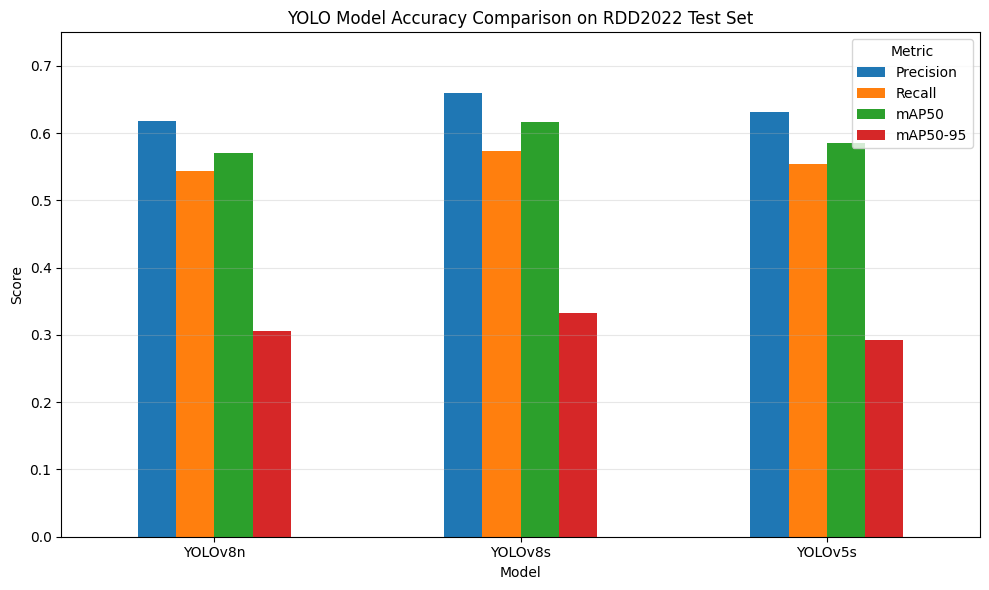

In [30]:
metrics_to_plot = [
    "Precision",
    "Recall",
    "mAP50",
    "mAP50-95"
]

plot_data = comparison_results.set_index("Model")[metrics_to_plot]

ax = plot_data.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("YOLO Model Accuracy Comparison on RDD2022 Test Set")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 0.75)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Metric")
plt.tight_layout()

plt.savefig(
    "/kaggle/working/test_results/accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

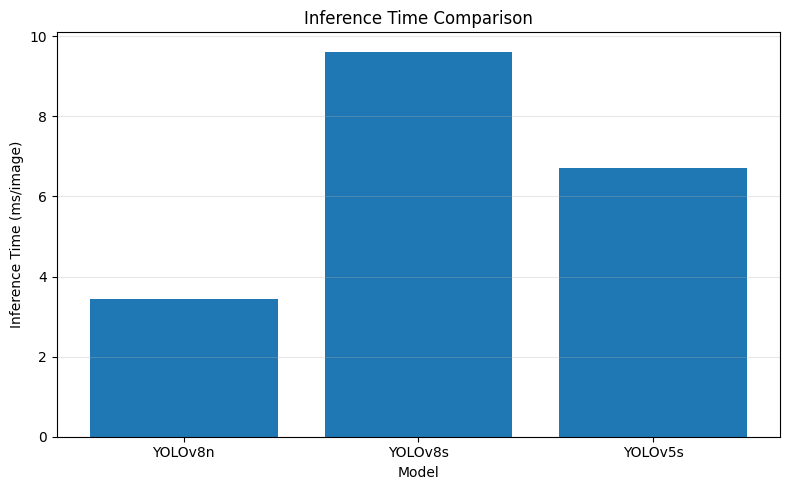

In [31]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_results["Model"],
    comparison_results["Inference_ms"]
)

plt.title("Inference Time Comparison")
plt.ylabel("Inference Time (ms/image)")
plt.xlabel("Model")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/kaggle/working/test_results/inference_time_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

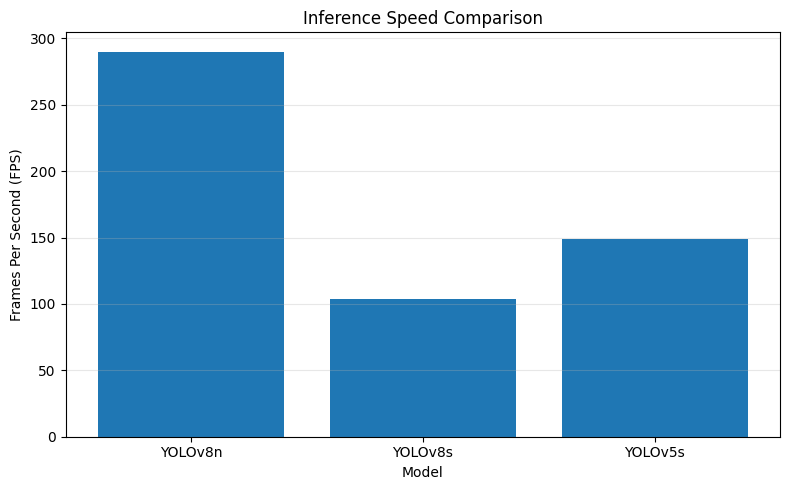

In [32]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_results["Model"],
    comparison_results["FPS"]
)

plt.title("Inference Speed Comparison")
plt.ylabel("Frames Per Second (FPS)")
plt.xlabel("Model")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/kaggle/working/test_results/fps_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

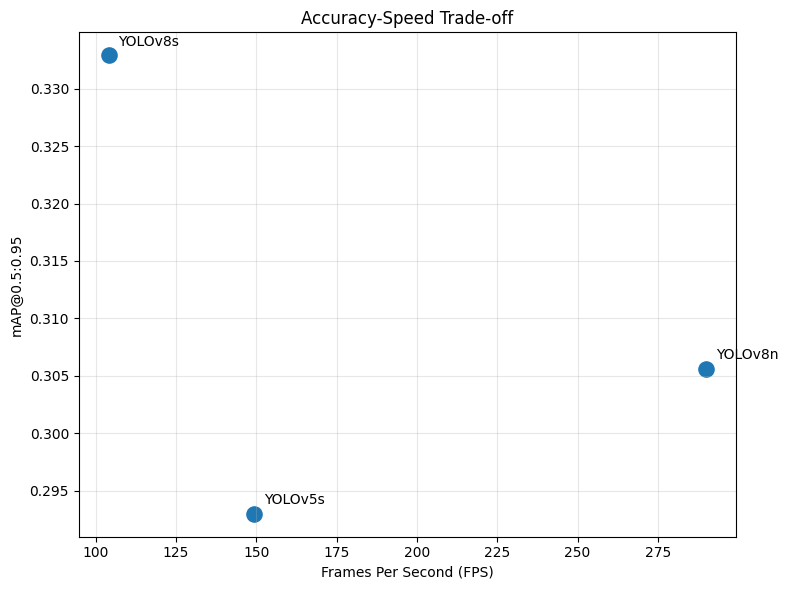

In [33]:
plt.figure(figsize=(8, 6))

plt.scatter(
    comparison_results["FPS"],
    comparison_results["mAP50-95"],
    s=120
)

for _, row in comparison_results.iterrows():
    plt.annotate(
        row["Model"],
        (row["FPS"], row["mAP50-95"]),
        xytext=(7, 7),
        textcoords="offset points"
    )

plt.title("Accuracy-Speed Trade-off")
plt.xlabel("Frames Per Second (FPS)")
plt.ylabel("mAP@0.5:0.95")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/kaggle/working/test_results/accuracy_speed_tradeoff.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 8. Ranking and per-class comparison

Prints which model is best on mAP and on speed, then builds the per-class tables (the YOLOv5s per-class values are typed in from its `val.py` output), saves them, finds the best model for each class and plots the per-class mAP@0.5:0.95.

In [34]:
best_accuracy = comparison_results.loc[
    comparison_results["mAP50-95"].idxmax()
]

best_speed = comparison_results.loc[
    comparison_results["FPS"].idxmax()
]

best_map50 = comparison_results.loc[
    comparison_results["mAP50"].idxmax()
]

print("FINAL MODEL RANKING")
print("=" * 60)

print(
    f"Best mAP50-95: "
    f"{best_accuracy['Model']} "
    f"({best_accuracy['mAP50-95']:.4f})"
)

print(
    f"Best mAP50: "
    f"{best_map50['Model']} "
    f"({best_map50['mAP50']:.4f})"
)

print(
    f"Fastest model: "
    f"{best_speed['Model']} "
    f"({best_speed['FPS']:.2f} FPS)"
)

FINAL MODEL RANKING
Best mAP50-95: YOLOv8s (0.3329)
Best mAP50: YOLOv8s (0.6170)
Fastest model: YOLOv8n (290.03 FPS)


In [35]:
# Create YOLOv5 per-class DataFrame
v5_per_class = pd.DataFrame({
    "Class Name": [
        "longitudinal crack",
        "transverse crack",
        "alligator crack",
        "other corruption",
        "Pothole"
    ],
    "Precision": [0.599, 0.605, 0.689, 0.674, 0.590],
    "Recall": [0.562, 0.439, 0.563, 0.729, 0.476],
    "mAP50": [0.572, 0.484, 0.634, 0.734, 0.507],
    "mAP50-95": [0.289, 0.215, 0.309, 0.435, 0.215]
})

# Keep only required columns
v8n_df = v8n_per_class[["Class Name", "mAP50", "mAP50-95"]].copy()
v8s_df = v8s_per_class[["Class Name", "mAP50", "mAP50-95"]].copy()
v5_df = v5_per_class[["Class Name", "mAP50", "mAP50-95"]].copy()

# Rename columns
v8n_df.columns = ["Class Name", "YOLOv8n mAP50", "YOLOv8n mAP50-95"]
v8s_df.columns = ["Class Name", "YOLOv8s mAP50", "YOLOv8s mAP50-95"]
v5_df.columns = ["Class Name", "YOLOv5s mAP50", "YOLOv5s mAP50-95"]

# Merge
per_class_comparison = (
    v8n_df
    .merge(v8s_df, on="Class Name")
    .merge(v5_df, on="Class Name")
)

display(per_class_comparison)

,Class Name,YOLOv8n mAP50,YOLOv8n mAP50-95,YOLOv8s mAP50,YOLOv8s mAP50-95,YOLOv5s mAP50,YOLOv5s mAP50-95
0,longitudinal crack,0.538537,0.296153,0.579859,0.322937,0.572,0.289
1,transverse crack,0.522995,0.253692,0.559511,0.278192,0.484,0.215
2,alligator crack,0.641208,0.338665,0.672695,0.354583,0.634,0.309
3,other corruption,0.721788,0.448060,0.755137,0.472972,0.734,0.435
4,Pothole,0.431501,0.191260,0.517736,0.235910,0.507,0.215


In [36]:
per_class_comparison.to_csv(
    "/kaggle/working/test_results/per_class_comparison.csv",
    index=False
)

print("Saved:")
print("/kaggle/working/test_results/per_class_comparison.csv")

Saved:
/kaggle/working/test_results/per_class_comparison.csv


In [37]:
summary_rows = []

for _, row in per_class_comparison.iterrows():

    scores = {
        "YOLOv8n": row["YOLOv8n mAP50-95"],
        "YOLOv8s": row["YOLOv8s mAP50-95"],
        "YOLOv5s": row["YOLOv5s mAP50-95"],
    }

    best_model = max(scores, key=scores.get)

    summary_rows.append({
        "Class": row["Class Name"],
        "Best Model": best_model,
        "Best mAP50-95": scores[best_model]
    })

best_per_class = pd.DataFrame(summary_rows)

display(best_per_class)

,Class,Best Model,Best mAP50-95
0,longitudinal crack,YOLOv8s,0.322937
1,transverse crack,YOLOv8s,0.278192
2,alligator crack,YOLOv8s,0.354583
3,other corruption,YOLOv8s,0.472972
4,Pothole,YOLOv8s,0.235910


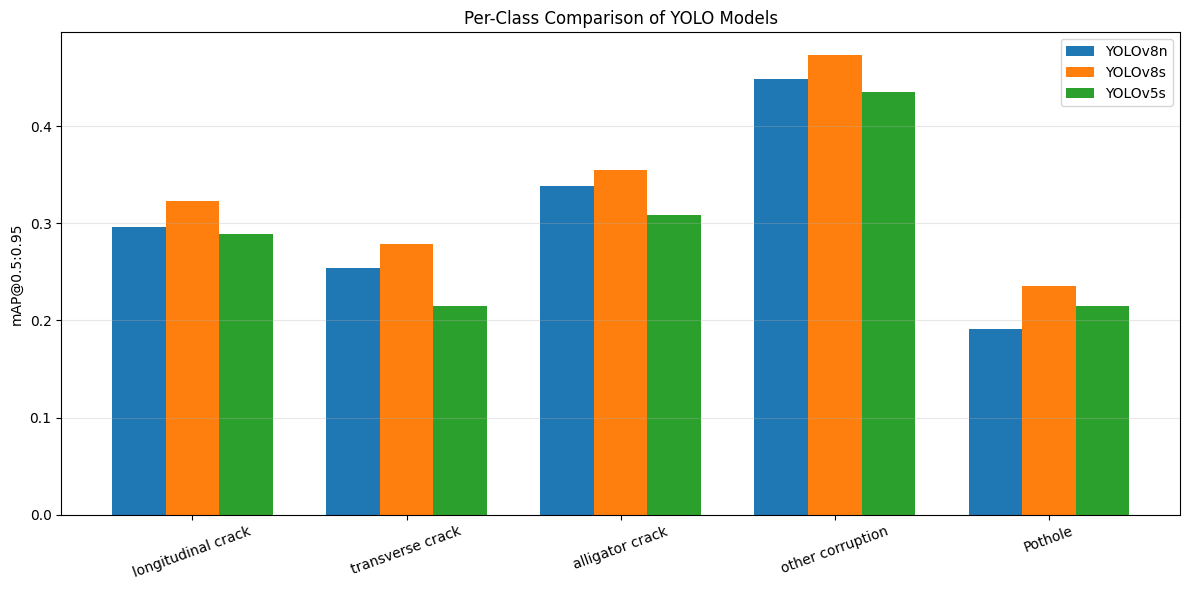

In [38]:
import numpy as np

classes = per_class_comparison["Class Name"]

x = np.arange(len(classes))
width = 0.25

plt.figure(figsize=(12,6))

plt.bar(
    x - width,
    per_class_comparison["YOLOv8n mAP50-95"],
    width,
    label="YOLOv8n"
)

plt.bar(
    x,
    per_class_comparison["YOLOv8s mAP50-95"],
    width,
    label="YOLOv8s"
)

plt.bar(
    x + width,
    per_class_comparison["YOLOv5s mAP50-95"],
    width,
    label="YOLOv5s"
)

plt.xticks(x, classes, rotation=20)
plt.ylabel("mAP@0.5:0.95")
plt.title("Per-Class Comparison of YOLO Models")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/kaggle/working/test_results/per_class_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()